# 10 - Transfer learning from a self-supervised Transformer (DistilBERT)
IMDB dataset, binary classification (positive / negative), with few labelled reviews

The networks of notebook 08 learn everything, including the word embeddings, from the labelled
reviews. DistilBERT is a small version of BERT (66 million parameters) that was pre-trained in a
self-supervised way (masked language modelling: predicting hidden words) on a large amount of text
without labels. It is a small example of a foundation model. We test the three ways of reusing it
that were discussed in class, with n = 100, 500 and 2,000 labelled reviews:

* **Zero-shot (no labels):** each review is compared with the frozen vectors of a few positive and
  negative sentences written by hand.
* **Feature extraction (transfer learning):** DistilBERT is frozen and gives one vector per review
  (the average of its outputs); only a logistic regression is trained on these vectors.
* **Fine-tuning:** all the weights of DistilBERT and a new output layer are trained with the n reviews.

They are compared with the Dense and CNN networks of notebook 08 trained from scratch with the same
n reviews. To keep the computation small (DistilBERT processes about 40 reviews per second on this
laptop), every model is evaluated on the same random subset of 2,000 test reviews, and DistilBERT
is fine-tuned with one seed. For n = 20,000 we reuse the predictions of notebook 08.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from transformers import AutoTokenizer, AutoModel, logging as hf_logging

from utils import set_style, save, SEED, RES_DIR, PURPLE, PINK, ORANGE, LILAC, PLUM, INK
from imdb_utils import *

hf_logging.set_verbosity_error()
set_style()
BERT = "distilbert-base-uncased"
SIZES = [100, 500, 2000]
SEEDS = [42, 43, 44]
PARTIAL = RES_DIR / "imdb_transfer_partial.csv"

## 1. Data

The same split as in notebook 08. For each n we take a stratified subset of n training reviews and
a validation subset of n / 4 reviews (at least 50) for early stopping, so that the amount of labelled
data is realistic. The vocabulary of the networks trained from scratch is the one of notebook 08
(it uses the texts of the training part, but not their labels).

In [2]:
d = prepare_imdb(256)
train_df, test_df = d["train_df"], d["test_df"]
idx_tr, idx_val = d["idx_tr"], d["idx_val"]
labels_all = train_df.label.values
test_sub = train_test_split(np.arange(len(test_df)), train_size=2000, stratify=test_df.label,
                            random_state=SEED)[0]
y_test = test_df.label.values[test_sub]

def subset(idx, n):
    return train_test_split(idx, train_size=n, stratify=labels_all[idx], random_state=SEED)[0]

subsets = {n: (subset(idx_tr, n), subset(idx_val, max(50, n // 4))) for n in SIZES}
for n, (a, b) in subsets.items():
    print(f"n = {n:5d}: {len(a)} training reviews ({labels_all[a].mean():.0%} positive), {len(b)} validation")

rows = pd.read_csv(PARTIAL).to_dict("records") if PARTIAL.exists() else []
done = {(r["strategy"], r["n"], r["seed"]) for r in rows}

def add(row):
    rows.append(row)
    pd.DataFrame(rows).to_csv(PARTIAL, index=False)
    print(f"{row['strategy']:42s} n = {row['n']:5d} seed {row['seed']}: {row['test accuracy']:.4f}")

n =   100: 100 training reviews (50% positive), 50 validation
n =   500: 500 training reviews (50% positive), 125 validation
n =  2000: 2000 training reviews (50% positive), 500 validation


## 2. Networks from scratch

With very few reviews there are very few updates per epoch, so the maximum number of epochs is 30
(patience 3). For n = 20,000 we use the test predictions of notebook 08 on the same 2,000 reviews.

In [3]:
X_all, L_all = encode([tokenize(t) for t in train_df.text], d["vocab"], 256)
y_all = torch.tensor(labels_all, dtype=torch.float32)
X_te, L_te = d["test"][0][test_sub], d["test"][1][test_sub]

for n in SIZES:
    tr, va = subsets[n]
    for name, build in [("Dense from scratch", lambda: DenseBag(d["vocab_size"])),
                        ("CNN from scratch", lambda: TextCNN(d["vocab_size"]))]:
        for seed in SEEDS:
            if (name, n, seed) in done:
                continue
            torch.manual_seed(seed)
            model = build()
            train_text_model(model, (X_all[tr], L_all[tr], y_all[tr]), (X_all[va], L_all[va], y_all[va]),
                             max_epochs=30, patience=3, seed=seed)
            add({"strategy": name, "n": n, "seed": seed,
                 "test accuracy": accuracy_score(y_test, predict_proba(model, X_te, L_te) > 0.5)})

probs_08 = pd.read_csv(RES_DIR / "imdb_test_probs.csv")
full = [{"strategy": f"{m} from scratch", "n": 20000, "seed": s,
         "test accuracy": accuracy_score(y_test, probs_08[f"{m}_{s}"].values[test_sub] > 0.5)}
        for m in ["Dense", "CNN"] for s in SEEDS]

Dense from scratch                         n =   100 seed 42: 0.6245


Dense from scratch                         n =   100 seed 43: 0.6320


Dense from scratch                         n =   100 seed 44: 0.5910


CNN from scratch                           n =   100 seed 42: 0.5315


CNN from scratch                           n =   100 seed 43: 0.6210


CNN from scratch                           n =   100 seed 44: 0.5970


... (8 outputs left out)

Dense from scratch                         n =  2000 seed 44: 0.7960


CNN from scratch                           n =  2000 seed 42: 0.8005


CNN from scratch                           n =  2000 seed 43: 0.8050


CNN from scratch                           n =  2000 seed 44: 0.8075


## 3. DistilBERT: tokenizer and frozen features

DistilBERT has its own tokenizer, which splits rare words into sub-words, so there are no unknown
words. The reviews are truncated to 256 tokens, as for the other networks.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(BERT)
print(tokenizer.tokenize("This movie was unwatchable, a total waste of time!"))

def bert_inputs(texts):
    texts = [t.replace("<br />", " ") for t in texts]
    enc = tokenizer(texts, truncation=True, max_length=256, padding="max_length", return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"]

needed = np.unique(np.concatenate([np.concatenate(s) for s in subsets.values()]))
ids_train = torch.zeros((len(train_df), 256), dtype=torch.long)
mask_train = torch.zeros((len(train_df), 256), dtype=torch.long)
ids_train[needed], mask_train[needed] = bert_inputs(list(train_df.text.values[needed]))
ids_test, mask_test = bert_inputs(list(test_df.text.values[test_sub]))
print(f"{len(needed)} training/validation reviews and {len(test_sub)} test reviews tokenised")

['this', 'movie', 'was', 'un', '##watch', '##able', ',', 'a', 'total', 'waste', 'of', 'time', '!']


2500 training/validation reviews and 2000 test reviews tokenised


In [5]:
def mean_pool(hidden, mask):
    m = mask.unsqueeze(-1).float()
    return (hidden * m).sum(1) / m.sum(1).clamp(min=1)

@torch.no_grad()
def bert_features(encoder, ids, mask, batch_size=64):
    encoder.eval()
    out = []
    for i in range(0, len(ids), batch_size):
        m = mask[i:i + batch_size].to(DEVICE)
        h = encoder(input_ids=ids[i:i + batch_size].to(DEVICE), attention_mask=m).last_hidden_state
        out.append(mean_pool(h, m).cpu())
    return torch.cat(out).numpy()

encoder = AutoModel.from_pretrained(BERT).to(DEVICE)
start = time.time()
feats_train = np.zeros((len(train_df), 768), dtype=np.float32)
feats_train[needed] = bert_features(encoder, ids_train[needed], mask_train[needed])
feats_test = bert_features(encoder, ids_test, mask_test)
print(f"Frozen features of {len(needed) + len(test_sub):,} reviews in {time.time() - start:.0f} s")

Frozen features of 4,500 reviews in 103 s


**Zero-shot:** no labelled review is used. A review is positive if its vector is closer (cosine
similarity) to the average vector of the positive sentences than to the negative ones.

In [6]:
POS = ["This movie was great, I loved it.", "A wonderful film with brilliant acting.",
       "One of the best movies I have ever seen.", "I really enjoyed it, highly recommended."]
NEG = ["This movie was terrible, I hated it.", "An awful film with horrible acting.",
       "One of the worst movies I have ever seen.", "A boring waste of time, do not watch it."]
proto = bert_features(encoder, *bert_inputs(POS + NEG))
p_pos, p_neg = proto[:4].mean(0), proto[4:].mean(0)
cos = lambda a, b: (a @ b) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b))
zero_shot = (cos(feats_test, p_pos) > cos(feats_test, p_neg)).astype(int)
acc_zs = accuracy_score(y_test, zero_shot)
print(f"Zero-shot accuracy: {acc_zs:.4f} (predicted positive: {zero_shot.mean():.1%})")
print("cosine similarity between the positive and the negative prototype:",
      round(float(p_pos @ p_neg / np.linalg.norm(p_pos) / np.linalg.norm(p_neg)), 3))
del encoder

Zero-shot accuracy: 0.6560 (predicted positive: 18.2%)
cosine similarity between the positive and the negative prototype: 0.932


**Feature extraction:** logistic regression on the frozen vectors (no gradient goes into DistilBERT).

In [7]:
for n in SIZES:
    tr, _ = subsets[n]
    scaler = StandardScaler().fit(feats_train[tr])
    clf = LogisticRegression(max_iter=3000, C=0.1).fit(scaler.transform(feats_train[tr]), labels_all[tr])
    acc = accuracy_score(y_test, clf.predict(scaler.transform(feats_test)))
    rows = [r for r in rows if not (r["strategy"].startswith("DistilBERT features") and r["n"] == n)]
    add({"strategy": "DistilBERT features + logistic regression", "n": n, "seed": SEED, "test accuracy": acc})

DistilBERT features + logistic regression  n =   100 seed 42: 0.7785
DistilBERT features + logistic regression  n =   500 seed 42: 0.7995


DistilBERT features + logistic regression  n =  2000 seed 42: 0.8330


## 4. Fine-tuning DistilBERT

A new linear layer is added on the average of the outputs and all the weights are trained with AdamW
(learning rate 2e-5, batch 16, gradient clipping), at most 3 epochs with early stopping (patience 1)
on the validation loss. One seed per n.

In [8]:
class BertClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(BERT)
        self.fc = nn.Linear(768, 1)

    def forward(self, ids, mask):
        h = self.encoder(input_ids=ids, attention_mask=mask).last_hidden_state
        return self.fc(mean_pool(h, mask)).squeeze(1)

@torch.no_grad()
def bert_predict(model, ids, mask, batch_size=64):
    model.eval()
    return torch.cat([torch.sigmoid(model(ids[i:i + batch_size].to(DEVICE),
                                          mask[i:i + batch_size].to(DEVICE))).cpu()
                      for i in range(0, len(ids), batch_size)]).numpy()

def fine_tune(tr, va, seed, lr=2e-5, batch_size=16, max_epochs=3, patience=1):
    torch.manual_seed(seed)
    model = BertClassifier().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    y_tr = torch.tensor(labels_all[tr], dtype=torch.float32)
    y_va = labels_all[va]
    g = torch.Generator().manual_seed(seed)
    best, best_state, wait, start = np.inf, None, 0, time.time()
    for epoch in range(max_epochs):
        model.train()
        for b in torch.randperm(len(tr), generator=g).split(batch_size):
            opt.zero_grad()
            loss = bce(model(ids_train[tr[b]].to(DEVICE), mask_train[tr[b]].to(DEVICE)), y_tr[b].to(DEVICE))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        p = np.clip(bert_predict(model, ids_train[va], mask_train[va]), 1e-6, 1 - 1e-6)
        val_loss = -np.mean(y_va * np.log(p) + (1 - y_va) * np.log(1 - p))
        print(f"  n = {len(tr)} epoch {epoch + 1}: validation loss {val_loss:.3f}")
        if val_loss < best:
            best, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, time.time() - start

for n in SIZES:
    if ("DistilBERT fine-tuning", n, SEED) in done:
        continue
    tr, va = subsets[n]
    model, secs = fine_tune(tr, va, SEED)
    add({"strategy": "DistilBERT fine-tuning", "n": n, "seed": SEED, "seconds": secs,
         "test accuracy": accuracy_score(y_test, bert_predict(model, ids_test, mask_test) > 0.5)})
    del model
    if DEVICE.type == "mps":
        torch.mps.empty_cache()

  n = 100 epoch 1: validation loss 0.687


  n = 100 epoch 2: validation loss 0.663


  n = 100 epoch 3: validation loss 0.606


DistilBERT fine-tuning                     n =   100 seed 42: 0.7220


  n = 500 epoch 1: validation loss 0.448


  n = 500 epoch 2: validation loss 0.528


DistilBERT fine-tuning                     n =   500 seed 42: 0.8075


  n = 2000 epoch 1: validation loss 0.309


  n = 2000 epoch 2: validation loss 0.375


DistilBERT fine-tuning                     n =  2000 seed 42: 0.8660


In [9]:
runs = pd.concat([pd.DataFrame(rows), pd.DataFrame(full)], ignore_index=True)
runs = pd.concat([runs, pd.DataFrame([{"strategy": "Zero-shot (no labels)", "n": 0, "seed": SEED,
                                       "test accuracy": acc_zs}])], ignore_index=True)
runs.to_csv(RES_DIR / "imdb_transfer_runs.csv", index=False)
summary = runs.groupby(["strategy", "n"], sort=False)["test accuracy"].agg(["mean", "std", "count"])
summary.to_csv(RES_DIR / "imdb_transfer_summary.csv")
summary.round(4)

mean     std  count
strategy                                  n                           
Dense from scratch                        100    0.6158  0.0218      3
CNN from scratch                          100    0.5832  0.0463      3
Dense from scratch                        500    0.7317  0.0097      3
CNN from scratch                          500    0.7410  0.0080      3
Dense from scratch                        2000   0.7848  0.0099      3
CNN from scratch                          2000   0.8043  0.0035      3
DistilBERT features + logistic regression 100    0.7785     NaN      1
                                          500    0.7995     NaN      1
                                          2000   0.8330     NaN      1
DistilBERT fine-tuning                    100    0.7220     NaN      1
                                          500    0.8075     NaN      1
                                          2000   0.8660     NaN      1
Dense from scratch                        20000  0.8627  0.0026      3
CNN from scratch                          20000  0.8643  0.0020      3
Zero-shot (no labels)                     0      0.6560     NaN      1

## 5. Results

Figure saved -> ../results/figures/imdb_transfer_curve.png


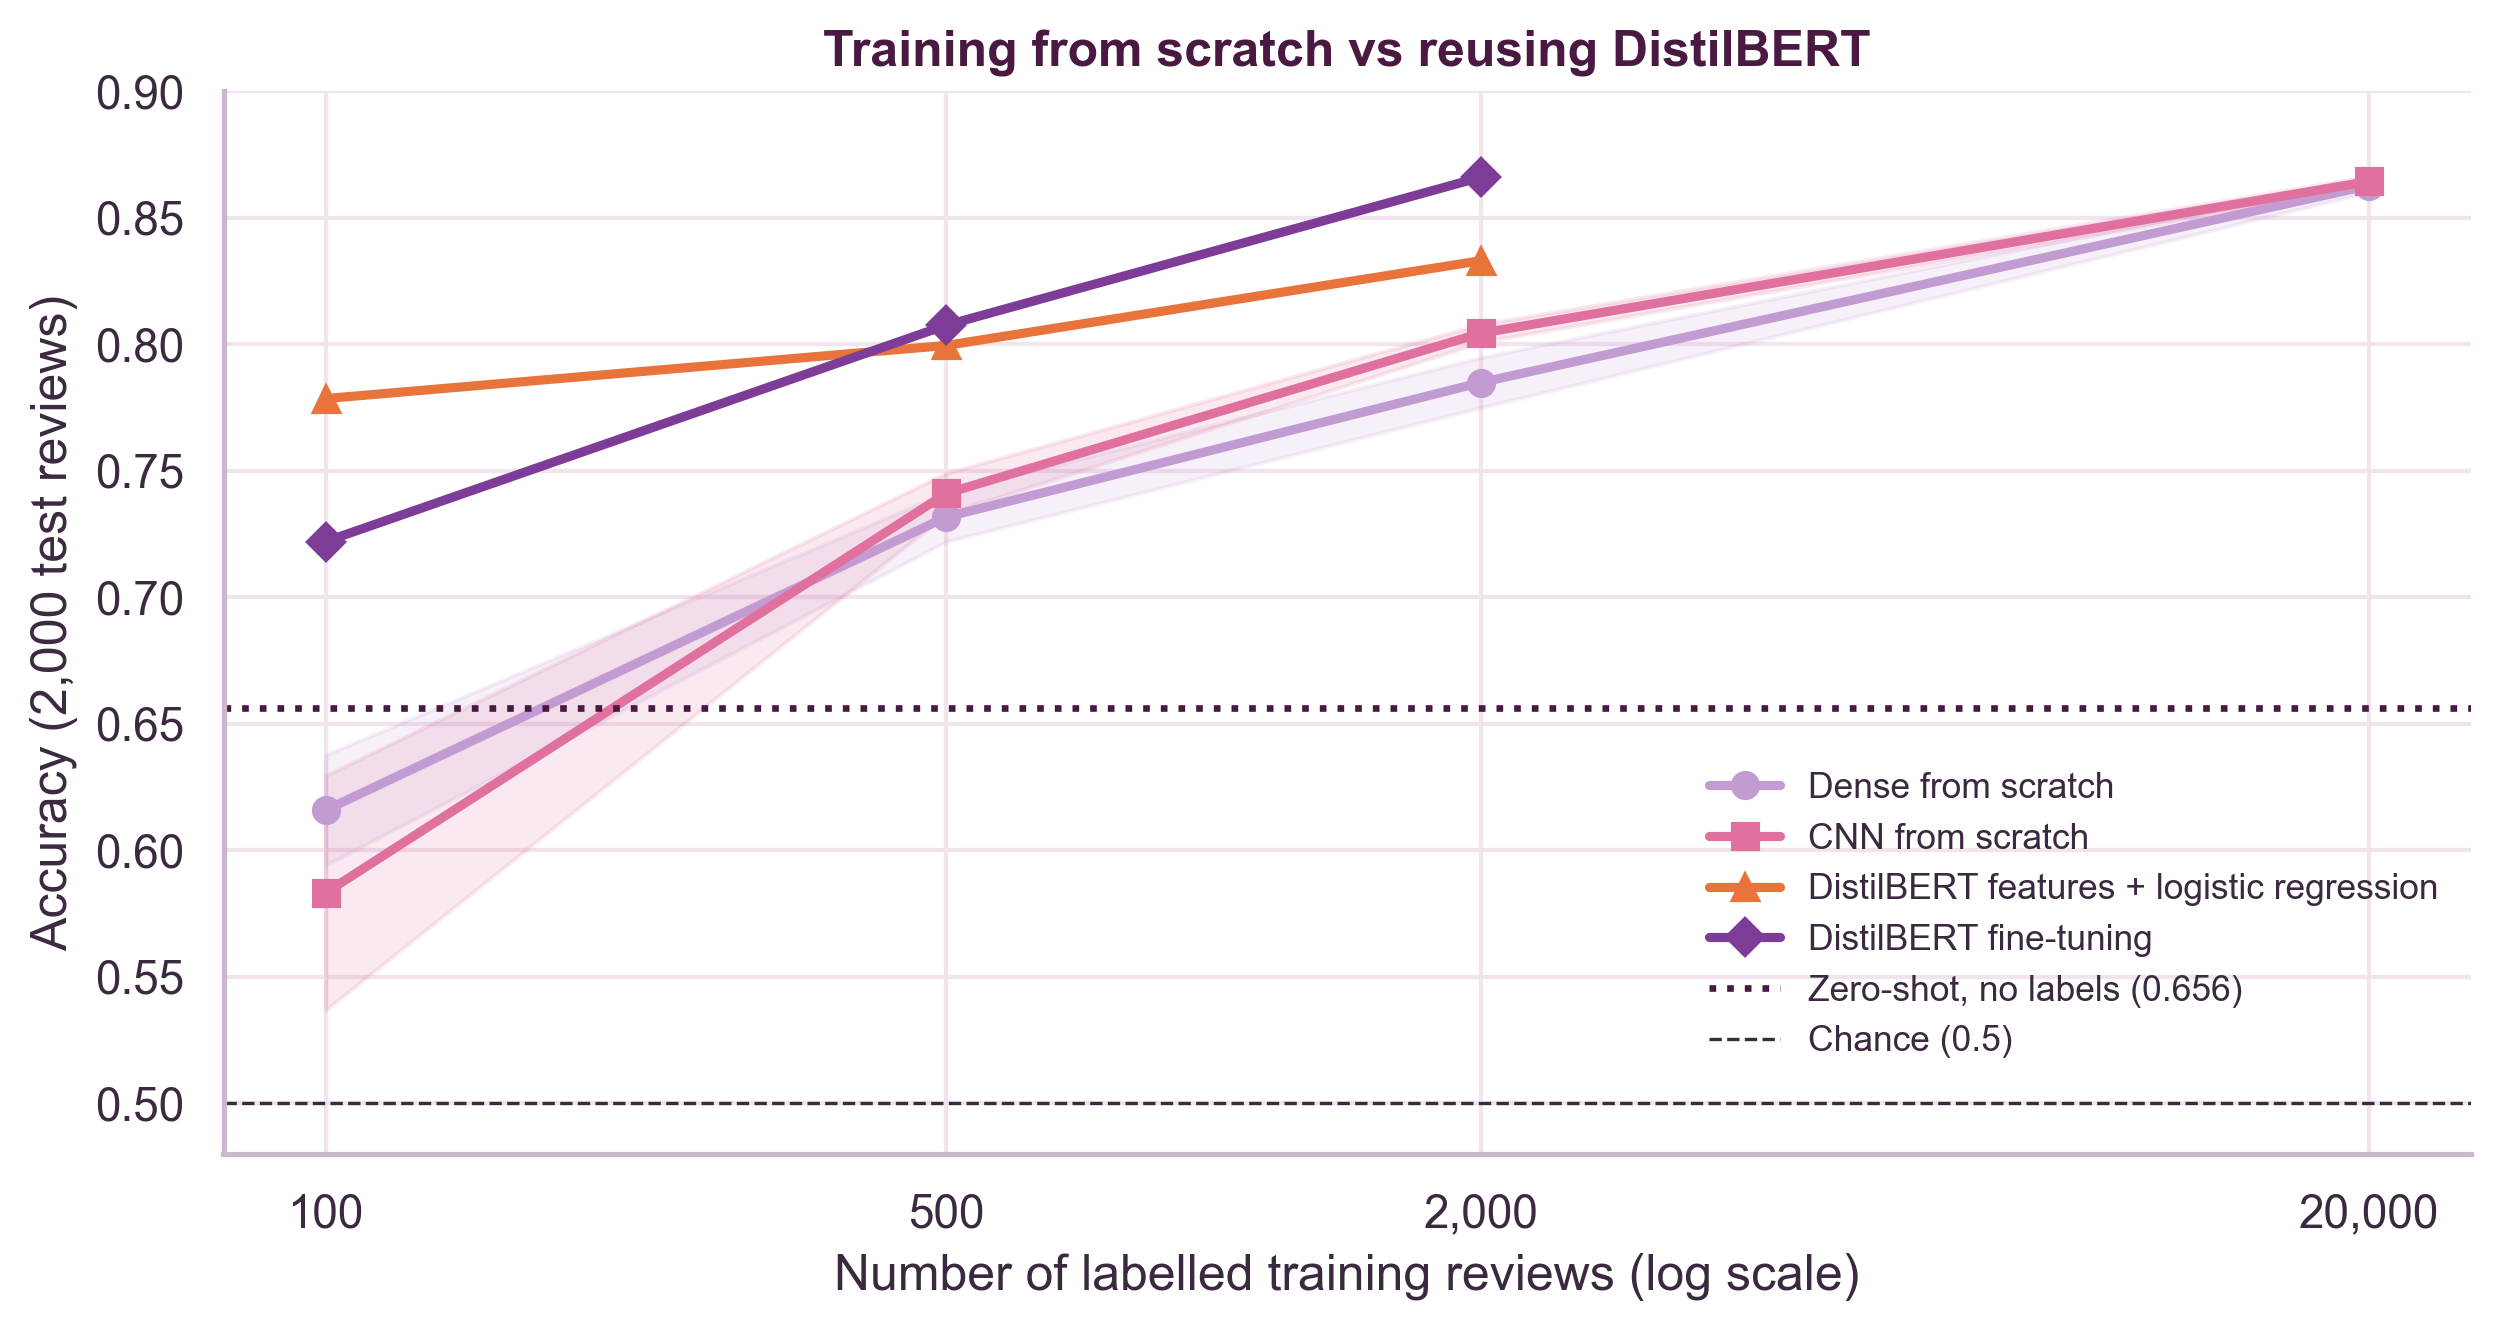

In [10]:
STRATS = [("Dense from scratch", LILAC, "o"), ("CNN from scratch", PINK, "s"),
          ("DistilBERT features + logistic regression", ORANGE, "^"), ("DistilBERT fine-tuning", PURPLE, "D")]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for name, col, mk in STRATS:
    s = runs[runs.strategy == name].groupby("n")["test accuracy"].agg(["mean", "std"]).fillna(0)
    ax.plot(s.index, s["mean"], marker=mk, color=col, lw=2.2, label=name)
    ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=col, alpha=0.15)
ax.axhline(acc_zs, color=PLUM, ls=":", lw=1.6, label=f"Zero-shot, no labels ({acc_zs:.3f})")
ax.axhline(0.5, color=INK, ls="--", lw=0.8, label="Chance (0.5)")
ax.set_xscale("log")
ax.set_xticks(SIZES + [20000], ["100", "500", "2,000", "20,000"])
ax.set_ylim(0.48, 0.9)
ax.set_xlabel("Number of labelled training reviews (log scale)")
ax.set_ylabel("Accuracy (2,000 test reviews)")
ax.set_title("Training from scratch vs reusing DistilBERT")
ax.legend(fontsize=8.5, loc="lower right", bbox_to_anchor=(1, 0.06))
fig.tight_layout()
save(fig, "imdb_transfer_curve.png")
plt.show()

## Summary

(Same 2,000 test reviews for every model; one seed for DistilBERT, so differences below about 0.01-0.02 are not meaningful.)

- **Few labels.** With 100 labelled reviews the networks from scratch are close to chance (Dense 0.616, CNN 0.583, very unstable), while a logistic regression on the frozen DistilBERT vectors reaches 0.779.
- **More labels.** The advantage of DistilBERT decreases with n, but fine-tuned with 2,000 reviews it reaches 0.866, the same as the networks from scratch with 20,000 reviews (0.863-0.864). The self-supervised pre-training is worth about ten times more labels.
- **Fine-tuning vs feature extraction.** Fine-tuning is worse with 100 reviews (0.722 vs 0.779, the validation loss was still decreasing after 3 epochs), similar with 500 (0.808 vs 0.800) and better with 2,000 (0.866 vs 0.833). With 500 and 2,000 reviews the best epoch was the first one.
- **Zero-shot.** 0.656 without any label: better than chance and than training from scratch with 100 reviews, but biased (only 18% predicted positive), because the mean-pooled DistilBERT vectors of the positive and negative prototypes are very similar (cosine 0.93).